<a href="https://colab.research.google.com/github/likhithakm-again/tsaf-lab04/blob/main/LAB_04_ARIMA_1RUA24CSE0223.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pandas numpy matplotlib statsmodels scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
# Load the AirPassengers dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

# Convert Month into datetime and set it as the index
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")

# Extract the passenger series
series = df["Passengers"].astype(float)

print("Dataset shape:", df.shape)
print("\nFirst five observations:")
print(df.head())

print("\nLast five observations:")
print(df.tail())

print("\nMissing values:", series.isna().sum())
print("Start date:", series.index.min())
print("End date:", series.index.max())

Dataset shape: (144, 1)

First five observations:
            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121

Last five observations:
            Passengers
Month                 
1960-08-01         606
1960-09-01         508
1960-10-01         461
1960-11-01         390
1960-12-01         432

Missing values: 0
Start date: 1949-01-01 00:00:00
End date: 1960-12-01 00:00:00


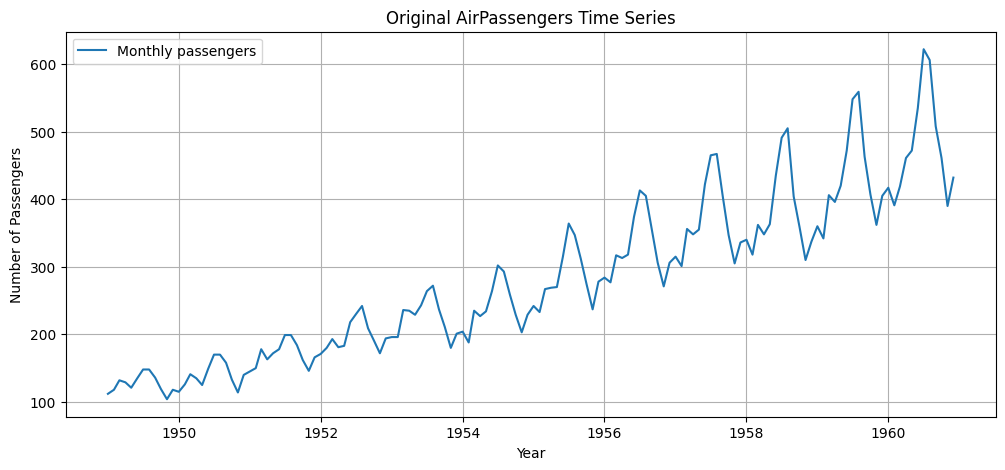

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(series, label="Monthly passengers")
plt.title("Original AirPassengers Time Series")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
adf_result = adfuller(series)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Number of lags used:", adf_result[2])
print("Number of observations:", adf_result[3])

alpha = 0.05

if adf_result[1] < alpha:
    print("Conclusion: Reject the null hypothesis. Evidence supports stationarity.")
else:
    print("Conclusion: Fail to reject the null hypothesis. The series may be non-stationary.")

ADF Statistic: 0.8153688792060528
p-value: 0.9918802434376411
Number of lags used: 13
Number of observations: 130
Conclusion: Fail to reject the null hypothesis. The series may be non-stationary.


/tmp/ipykernel_1655/2738569916.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)


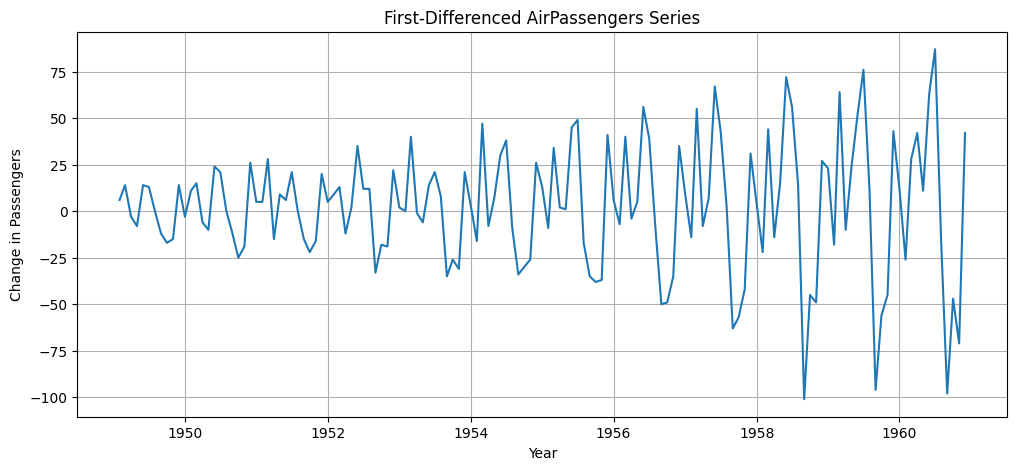

Original observations: 144
Differenced observations: 143

ADF statistic after differencing: -2.829266824169999
p-value after differencing: 0.05421329028382552


/tmp/ipykernel_1655/4236430579.py:15: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(diff_series)


In [ ]:
diff_series = series.diff().dropna()

plt.figure(figsize=(12, 5))
plt.plot(diff_series)
plt.title("First-Differenced AirPassengers Series")
plt.xlabel("Year")
plt.ylabel("Change in Passengers")
plt.grid(True)
plt.show()

print("Original observations:", len(series))
print("Differenced observations:", len(diff_series))

# Test stationarity after differencing
adf_diff = adfuller(diff_series)

print("\nADF statistic after differencing:", adf_diff[0])
print("p-value after differencing:", adf_diff[1])

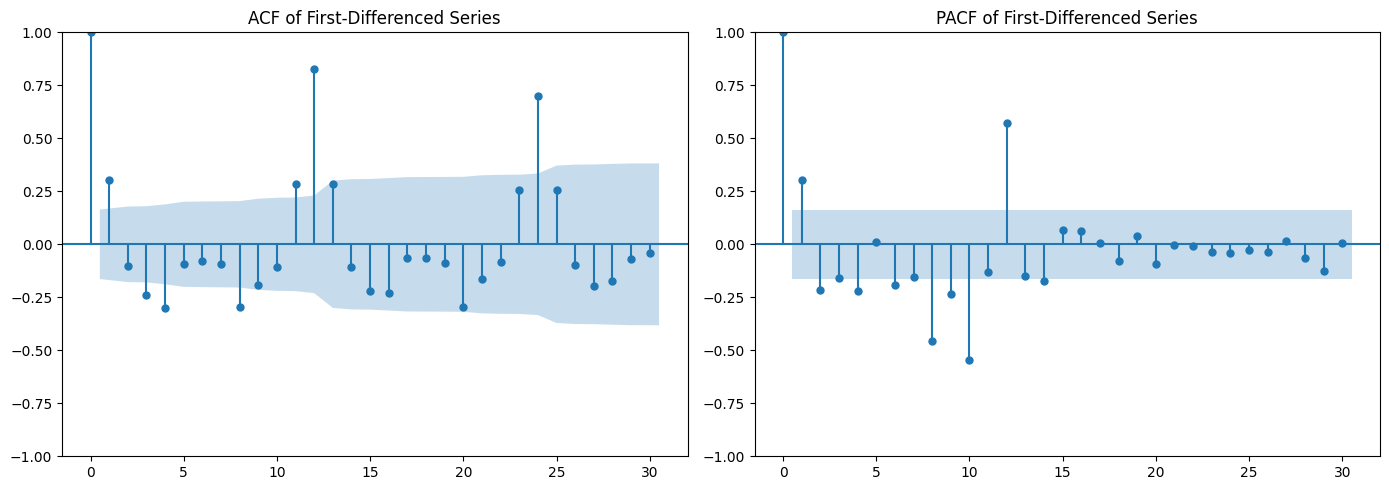

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(diff_series, ax=axes[0], lags=30)
plot_pacf(diff_series, ax=axes[1], lags=30, method="ywm")

axes[0].set_title("ACF of First-Differenced Series")
axes[1].set_title("PACF of First-Differenced Series")

plt.tight_layout()
plt.show()

In [ ]:
train_size = int(len(series) * 0.80)

train = series.iloc[:train_size]
test = series.iloc[train_size:]

print("Total observations:", len(series))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Total observations: 144
Training observations: 115
Testing observations: 29

Training period: 1949-01-01 00:00:00 to 1958-07-01 00:00:00
Testing period: 1958-08-01 00:00:00 to 1960-12-01 00:00:00


In [ ]:
model = ARIMA(train, order=(2, 1, 2))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -523.758
Date:                Thu, 29 Oct 2026   AIC                           1057.516
Time:                        13:27:37   BIC                           1071.197
Sample:                    01-01-1949   HQIC                          1063.069
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3280      0.145      2.268      0.023       0.045       0.611
ar.L2          0.2521      0.165      1.528      0.126      -0.071       0.575
ma.L1         -0.0125      0.109     -0.114      0.9

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
forecast = model_fit.forecast(steps=len(test))

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("ARIMA Order: (2, 1, 2)")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

ARIMA Order: (2, 1, 2)
MAE: 63.5453
RMSE: 82.513


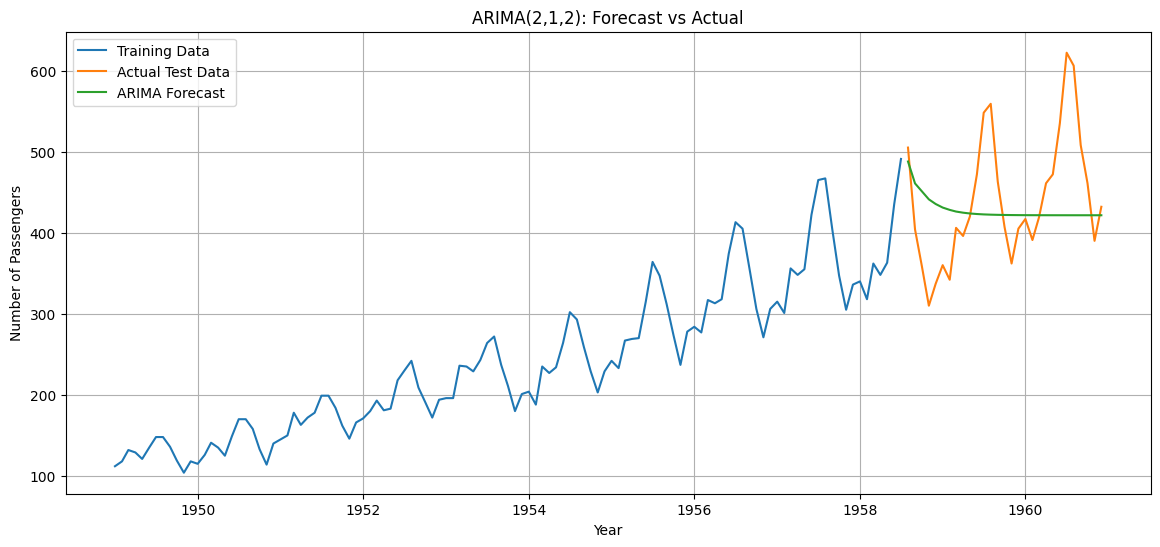

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Actual Test Data")
plt.plot(test.index, forecast, label="ARIMA Forecast")

plt.title("ARIMA(2,1,2): Forecast vs Actual")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.show()

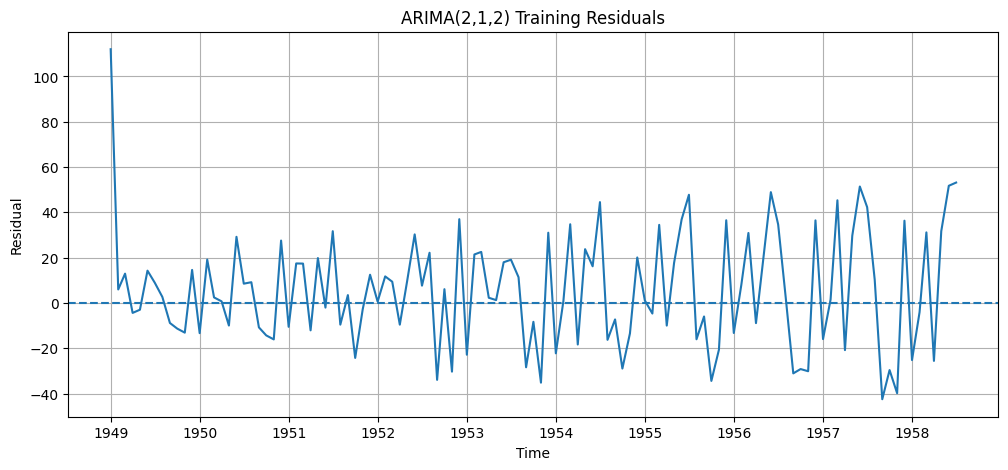

Residual mean: 5.7851
Residual standard deviation: 25.404


In [ ]:
residuals = model_fit.resid

plt.figure(figsize=(12, 5))
plt.plot(residuals)
plt.axhline(y=0, linestyle="--")
plt.title("ARIMA(2,1,2) Training Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

print("Residual mean:", round(residuals.mean(), 4))
print("Residual standard deviation:", round(residuals.std(), 4))

In [ ]:
print(f"MAE = {mae:.4f}")
print(f"RMSE = {rmse:.4f}")

MAE = 63.5453
RMSE = 82.5130


###Independent Task 4.1: Change the ARIMA order

In [ ]:
orders = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

results = []

for order in orders:
    try:
        fitted_model = ARIMA(train, order=order).fit()
        forecast_values = fitted_model.forecast(steps=len(test))

        results.append({
            "ARIMA Order": str(order),
            "AIC": fitted_model.aic,
            "MAE": mean_absolute_error(test, forecast_values),
            "RMSE": np.sqrt(
                mean_squared_error(test, forecast_values)
            )
        })

    except Exception as e:
        print(f"Model {order} failed: {e}")

comparison_df = pd.DataFrame(results)
print(comparison_df.round(4).to_string(index=False))

best_model = comparison_df.loc[comparison_df["RMSE"].idxmin()]
print("\nModel with the lowest test RMSE:")
print(best_model)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

ARIMA Order       AIC     MAE    RMSE
  (1, 1, 1) 1058.2456 85.2542 97.4996
  (2, 1, 1) 1058.6476 60.5290 82.6211
  (1, 1, 2) 1057.3275 62.0635 82.6358
  (2, 1, 2) 1057.5162 63.5453 82.5130

Model with the lowest test RMSE:
ARIMA Order      (2, 1, 2)
AIC            1057.516178
MAE              63.545311
RMSE             82.513011
Name: 3, dtype: object


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


The four ARIMA configurations were compared using AIC, MAE, and RMSE on the same test dataset. ARIMA(1,1,1) produced an AIC of 1058.2456, MAE of 85.2542, and RMSE of 97.4996, making it the least accurate model among the four based on the test errors. ARIMA(2,1,1) achieved an MAE of 60.5290 and RMSE of 82.6211, while ARIMA(1,1,2) achieved an MAE of 62.0635 and RMSE of 82.6358. ARIMA(2,1,2) had the lowest RMSE of 82.5130 and the lowest AIC of 1057.5162, although ARIMA(2,1,1) achieved the lowest MAE of 60.5290. Therefore, ARIMA(2,1,2) performed best according to AIC and RMSE, whereas ARIMA(2,1,1) produced the smallest average absolute forecasting error. The results demonstrate that changing the AR and MA orders affects forecasting performance, and model selection should consider multiple evaluation criteria.



### Independent Task 4.2: Effect of differencing

In [ ]:
d_results = []

for d in [0, 1]:
    try:
        fitted_model = ARIMA(
            train,
            order=(2, d, 2)
        ).fit()

        forecast_values = fitted_model.forecast(
            steps=len(test)
        )

        d_results.append({
            "ARIMA Order": f"(2,{d},2)",
            "AIC": fitted_model.aic,
            "MAE": mean_absolute_error(test, forecast_values),
            "RMSE": np.sqrt(
                mean_squared_error(test, forecast_values)
            )
        })

    except Exception as e:
        print(f"Model with d={d} failed: {e}")

print(pd.DataFrame(d_results).round(4).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros 

ARIMA Order       AIC     MAE     RMSE
    (2,0,2) 1074.5413 92.2417 114.8879
    (2,1,2) 1057.5162 63.5453  82.5130


ARIMA(2,0,2) produced an AIC of 1074.5413, MAE of 92.2417, and RMSE of 114.8879. In comparison, ARIMA(2,1,2) achieved a lower AIC of 1057.5162, MAE of 63.5453, and RMSE of 82.5130. The model with first order differencing performed considerably better across all three metrics. Without differencing, the model may struggle to represent the changing level and trend in the original passenger series. Applying first order differencing reduces the trend and helps the model represent the data more effectively. These results indicate that using d=1 was more appropriate than d=0 for this dataset and the selected model configurations.

### Independent Task 4.3: Forecast horizon

In [ ]:
horizon_model = ARIMA(train, order=(2, 1, 2)).fit()

horizons = [6, 12, 24]
horizon_results = []

for h in horizons:

    predictions = horizon_model.forecast(steps=h)
    actual = test.iloc[:h]

    horizon_results.append({
        "Horizon (months)": h,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predictions)
        )
    })

print(pd.DataFrame(horizon_results).round(4).to_string(index=False))

 Horizon (months)     MAE    RMSE
                6 77.7872 85.5806
               12 64.9820 76.7748
               24 62.1027 79.9188


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


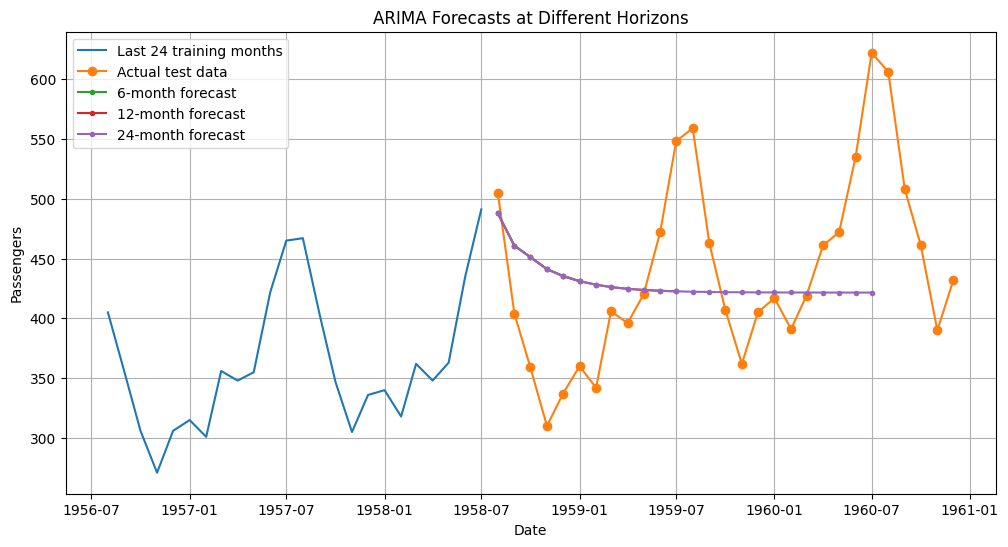

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(train.tail(24), label="Last 24 training months")
plt.plot(test, label="Actual test data", marker="o")

for h in horizons:
    pred = horizon_model.forecast(steps=h)
    plt.plot(
        pred.index,
        pred.values,
        marker=".",
        label=f"{h}-month forecast"
    )

plt.title("ARIMA Forecasts at Different Horizons")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True)
plt.show()

The ARIMA model was evaluated over forecast horizons of 6, 12, and 24 months. The six month forecast produced an MAE of 77.7872 and RMSE of 85.5806. The twelve month forecast achieved an MAE of 64.9820 and RMSE of 76.7748, while the twenty four month forecast produced an MAE of 62.1027 and RMSE of 79.9188. The twelve month horizon had the lowest RMSE, whereas the twenty four month horizon had the lowest MAE. The forecast plot shows that the model predictions gradually settle near 420 passengers and fail to reproduce the large seasonal peaks and troughs in the actual data. The errors do not increase consistently with the forecast horizon because each horizon is evaluated over a different number of observations. Overall, the results show that the model does not adequately capture the strong seasonal variations, even when evaluated over different forecast periods.

### Independent Task 4.4: Residual analysis

<Figure size 1000x400 with 0 Axes>

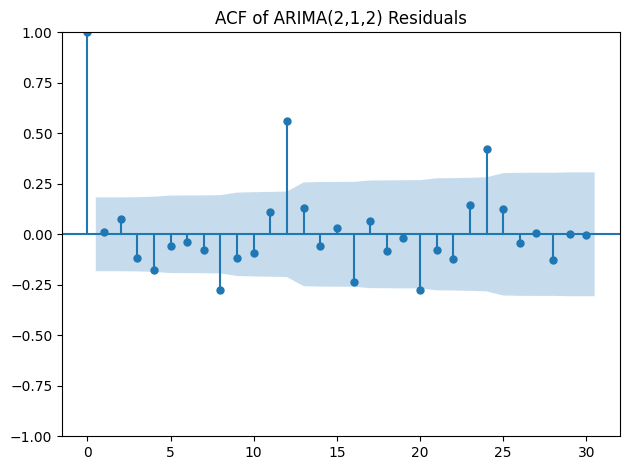

In [ ]:
residuals = horizon_model.resid

plt.figure(figsize=(10, 4))
plot_acf(residuals.dropna(), lags=30)
plt.title("ACF of ARIMA(2,1,2) Residuals")
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_results = acorr_ljungbox(
    residuals.dropna(),
    lags=[12, 24],
    return_df=True
)

print(lb_results)

       lb_stat     lb_pvalue
12   62.591775  7.574278e-09
24  118.106106  2.106928e-14


The residual ACF plot shows several spikes outside the confidence intervals, particularly around lags 8, 12, 20, and 24. This indicates that autocorrelation remains in the residuals and that the ARIMA model has not captured all the temporal patterns in the training data. The Ljung Box test produced a statistic of 62.5918 with a p value of approximately 7.57 × 10⁻⁹ at lag 12. At lag 24, the statistic was 118.1061 with a p value of approximately 2.11 × 10⁻¹⁴. Both p values are below 0.05, so the null hypothesis of no autocorrelation up to the tested lags is rejected. This confirms that significant autocorrelation remains in the residuals. Therefore, ARIMA(2,1,2) does not fully capture the structure of the AirPassengers series, and a seasonal model such as SARIMA should be considered.

### Independent Task 4.5: Use a new real-world dataset

Dataset source: statsmodels Sunspots dataset
Sampling frequency: Annual
Number of observations: 309
YEAR
1700     5.0
1701    11.0
1702    16.0
1703    23.0
1704    36.0
Name: SUNACTIVITY, dtype: float64


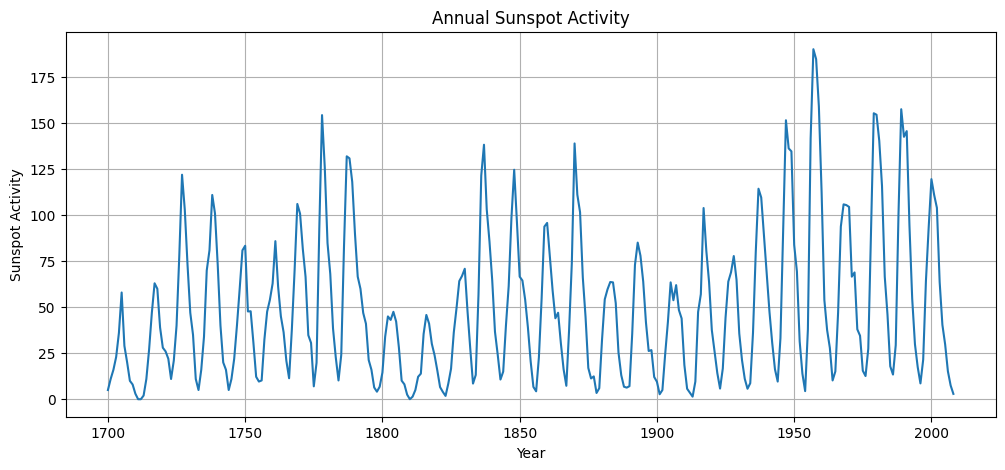

In [ ]:
import statsmodels.api as sm

sunspots_df = sm.datasets.sunspots.load_pandas().data

sunspots_df["YEAR"] = sunspots_df["YEAR"].astype(int)
sunspots_df = sunspots_df.set_index("YEAR")

sunspots = sunspots_df["SUNACTIVITY"].astype(float)

print("Dataset source: statsmodels Sunspots dataset")
print("Sampling frequency: Annual")
print("Number of observations:", len(sunspots))
print(sunspots.head())

plt.figure(figsize=(12, 5))
plt.plot(sunspots)
plt.title("Annual Sunspot Activity")
plt.xlabel("Year")
plt.ylabel("Sunspot Activity")
plt.grid(True)
plt.show()

Original ADF statistic: -2.8377807249381983
Original p-value: 0.053076421728120105


/tmp/ipykernel_1655/1515036838.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_original = adfuller(sunspots)


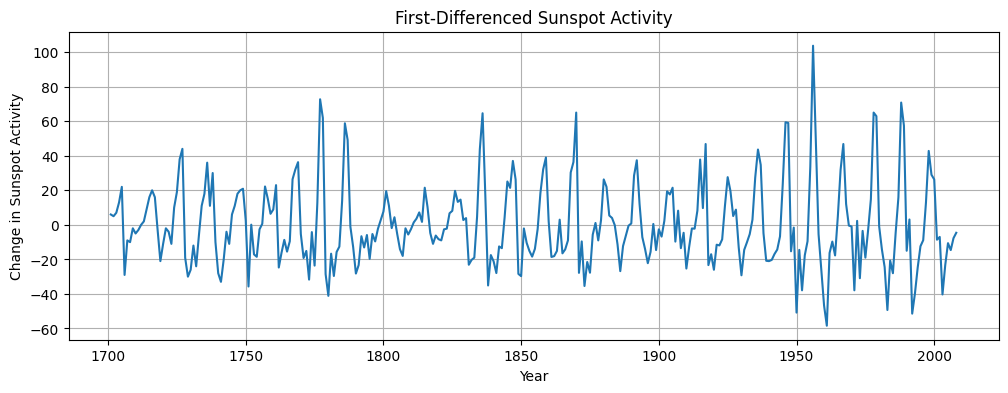

Differenced ADF statistic: -14.861663428129381
Differenced p-value: 1.715552423167157e-27


/tmp/ipykernel_1655/1515036838.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(sunspots_diff)


In [ ]:
adf_original = adfuller(sunspots)

print("Original ADF statistic:", adf_original[0])
print("Original p-value:", adf_original[1])

sunspots_diff = sunspots.diff().dropna()

plt.figure(figsize=(12, 4))
plt.plot(sunspots_diff)
plt.title("First-Differenced Sunspot Activity")
plt.xlabel("Year")
plt.ylabel("Change in Sunspot Activity")
plt.grid(True)
plt.show()

adf_diff = adfuller(sunspots_diff)

print("Differenced ADF statistic:", adf_diff[0])
print("Differenced p-value:", adf_diff[1])

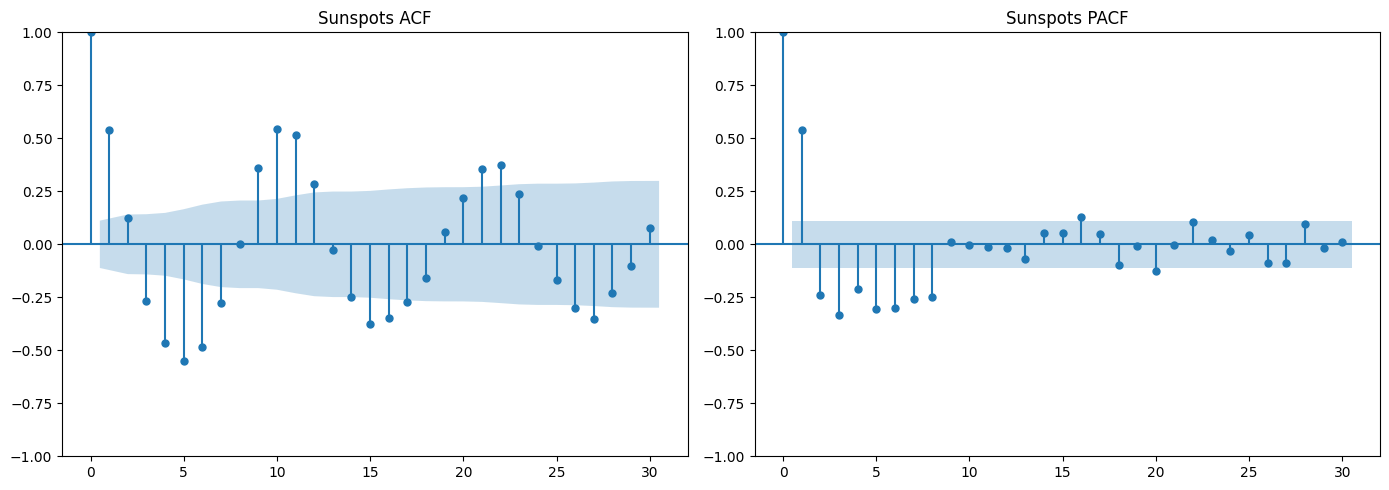

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(sunspots_diff, ax=axes[0], lags=30)
plot_pacf(sunspots_diff, ax=axes[1], lags=30, method="ywm")

axes[0].set_title("Sunspots ACF")
axes[1].set_title("Sunspots PACF")

plt.tight_layout()
plt.show()

Training observations: 247
Testing observations: 62
Training period: 1700-01-01 00:00:00 to 1946-01-01 00:00:00
Testing period: 1947-01-01 00:00:00 to 2008-01-01 00:00:00
                               SARIMAX Results                                
Dep. Variable:            SUNACTIVITY   No. Observations:                  247
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -1005.272
Date:                Thu, 29 Oct 2026   AIC                           2020.545
Time:                        13:35:25   BIC                           2038.071
Sample:                    01-01-1700   HQIC                          2027.602
                         - 01-01-1946                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5912      0.037     43

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


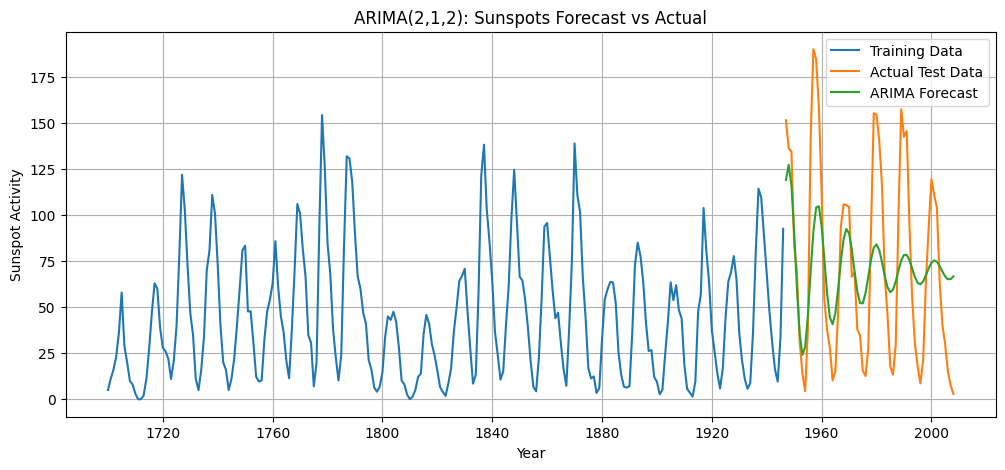

In [ ]:
sunspots.index = pd.date_range(
    start=f"{int(sunspots.index[0])}-01-01",
    periods=len(sunspots),
    freq="YS"
)

sunspots_train_size = int(len(sunspots) * 0.80)

sunspots_train = sunspots.iloc[:sunspots_train_size]
sunspots_test = sunspots.iloc[sunspots_train_size:]

print("Training observations:", len(sunspots_train))
print("Testing observations:", len(sunspots_test))
print("Training period:", sunspots_train.index.min(),
      "to", sunspots_train.index.max())
print("Testing period:", sunspots_test.index.min(),
      "to", sunspots_test.index.max())

sunspots_model = ARIMA(
    sunspots_train,
    order=(2, 1, 2)
).fit()

print(sunspots_model.summary())

sunspots_forecast = sunspots_model.forecast(
    steps=len(sunspots_test)
)

sunspots_mae = mean_absolute_error(
    sunspots_test, sunspots_forecast
)

sunspots_rmse = np.sqrt(
    mean_squared_error(sunspots_test, sunspots_forecast)
)

print("\nSunspots Forecasting Results")
print("Dataset: Sunspots")
print("Frequency: Annual")
print("ARIMA Order: (2,1,2)")
print(f"MAE: {sunspots_mae:.4f}")
print(f"RMSE: {sunspots_rmse:.4f}")

plt.figure(figsize=(12, 5))

plt.plot(
    sunspots_train.index,
    sunspots_train,
    label="Training Data"
)

plt.plot(
    sunspots_test.index,
    sunspots_test,
    label="Actual Test Data"
)

plt.plot(
    sunspots_test.index,
    sunspots_forecast,
    label="ARIMA Forecast"
)

plt.title("ARIMA(2,1,2): Sunspots Forecast vs Actual")
plt.xlabel("Year")
plt.ylabel("Sunspot Activity")
plt.legend()
plt.grid(True)
plt.show()

The Sunspots dataset from the statsmodels dataset collection was used as an additional real world univariate time series. It contains 309 annual observations of sunspot activity. The data were divided chronologically into 247 training observations and 62 testing observations, with the training period covering 1700 to 1946 and the testing period covering 1947 to 2008. The Augmented Dickey Fuller test on the original series produced a statistic of -2.8378 and a p value of 0.0531, which is slightly above the 0.05 significance level. After first order differencing, the ADF statistic decreased to -14.8617 and the p value was approximately 1.72 × 10⁻²⁷, providing strong evidence of stationarity in the differenced series. An ARIMA(2,1,2) model was fitted to the training data and evaluated on the test observations. The model achieved an MAE of 33.1613 and an RMSE of 40.2278. The forecast plot shows that the model captures some fluctuations in sunspot activity but does not fully reproduce the sharp peaks and troughs in the actual test series. Therefore, the experiment demonstrates the application of ARIMA to a second real dataset and shows that model accuracy depends on how well the selected configuration captures the underlying patterns.